In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
import statsmodels.stats.multicomp as mc
from IPython.display import display
import networkx as nx

## 1. Leitura dos dados

In [18]:
PASTA_PRECIP = os.path.join("..", "DATA", "CSV_regioes")   # precipitação
PASTA_ACUDES = os.path.join("..", "DATA", "CSV_acudes")    # volume dos açudes

def ler_pasta(pasta, sep=";", **kwargs):
    lista = []
    for nome in sorted(os.listdir(pasta)):
        if nome.lower().endswith(".csv"):
            df = pd.read_csv(os.path.join(pasta, nome), sep=sep, **kwargs)
            df["arquivo"] = os.path.splitext(nome)[0]
            lista.append(df)
    if not lista:
        raise FileNotFoundError(f"Nenhum CSV em: {pasta}")
    return lista

df_1 = pd.concat(ler_pasta(PASTA_PRECIP, decimal="."), ignore_index=True)
df_2 = pd.concat(ler_pasta(PASTA_ACUDES, decimal=","), ignore_index=True).rename(columns={"arquivo": "acude"})

display(df_1.head())
display(df_2.head())
print(df_1.dtypes, "\n")
print(df_2.dtypes)

,data,lat,lon,precip_mm,municipio,estado,uf,regiao,arquivo
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste,precipitacao_2006_com_local
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste,precipitacao_2006_com_local
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste,precipitacao_2006_com_local


,DateTime,Volume (hm³),acude
0,2006-01-01 00:00:00,42.59,reserv_atalho
1,2006-01-02 00:00:00,42.59,reserv_atalho
2,2006-01-03 00:00:00,NaN,reserv_atalho
3,2006-01-04 00:00:00,NaN,reserv_atalho
4,2006-01-05 00:00:00,NaN,reserv_atalho


data             str
lat          float64
lon          float64
precip_mm    float64
municipio        str
estado           str
uf               str
regiao           str
arquivo          str
dtype: object 

DateTime            str
Volume (hm³)    float64
acude               str
dtype: object


## 2. Pré-processamento dos açudes

- `pct`: volume em % da capacidade máxima (limitado a 100%).
- `classe_acude`: classe ordinal do volume (≤10% muito crítico, ≤30% crítico, ≤50% alerta, ≤70% confortável, >70% muito confortável).
- `status_alerta`: **0** = muito crítico ou crítico (≤30%), **1** = acima de 30%.

In [19]:
# Padroniza o nome do açude (o arquivo pode vir como 'olho_dagua' ou 'olhodgua')
df_2["acude"] = df_2["acude"].replace({"reserv_olho_dagua": "reserv_olhodgua"})

capacidade = {            # hm³
    "reserv_olhodgua":   19.210,
    "reserv_quixabinha": 31.780,
    "reserv_atalho":     72.550,
    "reserv_rosario":    47.220,
}

df_2["capacidade_maxima"] = df_2["acude"].map(capacidade).astype(float)
sem_capacidade = df_2.loc[df_2["capacidade_maxima"].isna(), "acude"].unique()
if len(sem_capacidade):
    print("ATENÇÃO: açudes sem capacidade cadastrada:", sem_capacidade)

df_2["pct"] = (df_2["Volume (hm³)"] / df_2["capacidade_maxima"] * 100).clip(upper=100)
pct = df_2["pct"]

condicoes = [
    (pct >= 0)  & (pct <= 10),
    (pct > 10)  & (pct <= 30),
    (pct > 30)  & (pct <= 50),
    (pct > 50)  & (pct <= 70),
    (pct > 70)  & (pct <= 100),
]
rotulos = ["muito_critico", "critico", "alerta", "confortavel", "muito_confortavel"]
df_2["classe_acude"] = np.select(condicoes, rotulos, default="sem_classe")
df_2.loc[pct.isna() | (df_2["classe_acude"] == "sem_classe"), "classe_acude"] = np.nan

# 0 = muito crítico/crítico (<=30%) | 1 = acima de 30%; NA onde não há volume
df_2["status_alerta"] = (pct > 30).astype("Int64").where(pct.notna())

print(df_2["classe_acude"].value_counts(dropna=False))
print(df_2["status_alerta"].value_counts(dropna=False))

classe_acude
muito_confortavel    8736
critico              6812
alerta               5039
confortavel          3786
NaN                  3142
muito_critico        2796
Name: count, dtype: int64
status_alerta
1       17561
0        9608
<NA>     3142
Name: count, dtype: Int64


## 3. Integração: açude × ponto de precipitação mais próximo

Cada açude é ligado ao ponto de chuva mais próximo (distância de Haversine, raio máximo de 50 km) e os dados são unidos pela data.

In [20]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Distância em km entre pontos (fórmula de Haversine)."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

coordenadas_acudes = pd.DataFrame({
    "acude":     ["reserv_atalho", "reserv_rosario", "reserv_olhodgua", "reserv_quixabinha"],
    "lat_acude": [-8.75, -6.75, -6.25, -7.25],
    "lon_acude": [-38.25, -39.25, -36.25, -38.75],
})
RAIO_MAXIMO_KM = 50.0

# chave de data em texto, igual nas duas tabelas
df_1["data_str"] = pd.to_datetime(df_1["data"]).dt.strftime("%Y-%m-%d")
df_2["data_str"] = pd.to_datetime(df_2["DateTime"]).dt.strftime("%Y-%m-%d")

# remove linhas repetidas de precipitação (mesma data e mesmo ponto)
antes = len(df_1)
df_1 = df_1.drop_duplicates(subset=["data_str", "lat", "lon"]).reset_index(drop=True)
print(f"Linhas repetidas removidas em df_1: {antes - len(df_1)}")

pontos = df_1[["lat", "lon"]].drop_duplicates().reset_index(drop=True)
mapeamento = []
for _, ac in coordenadas_acudes.iterrows():
    dist = haversine_km(ac["lat_acude"], ac["lon_acude"], pontos["lat"], pontos["lon"])
    i = dist.idxmin()
    if dist.loc[i] <= RAIO_MAXIMO_KM:
        mapeamento.append({
            "acude": ac["acude"],
            "lat_precip_mais_proxima": pontos.loc[i, "lat"],
            "lon_precip_mais_proxima": pontos.loc[i, "lon"],
            "distancia_km": dist.loc[i],
        })
    else:
        print(f"Açude '{ac['acude']}' ignorado: ponto de chuva mais próximo a {dist.loc[i]:.1f} km (limite {RAIO_MAXIMO_KM} km).")

df_map = pd.DataFrame(mapeamento)
if df_map.empty:
    raise ValueError("Nenhum açude atendeu ao critério de distância.")

df_2_geo = df_2.merge(df_map, on="acude", how="inner")
df_unificado = df_2_geo.merge(
    df_1,
    left_on=["data_str", "lat_precip_mais_proxima", "lon_precip_mais_proxima"],
    right_on=["data_str", "lat", "lon"],
    how="inner",
)
print(f"Registros válidos (raio de {RAIO_MAXIMO_KM} km): {len(df_unificado)}")
print(df_unificado["acude"].value_counts())

df_final = df_unificado.rename(columns={
    "DateTime": "Data",
    "Volume (hm³)": "volume",
    "precip_mm": "precipitação",
    "classe_acude": "classe_volume_acude",
    "status_alerta": "bin_status_alerta",
})
cols = ["Data", "acude", "municipio", "estado", "volume", "pct",
        "precipitação", "classe_volume_acude", "bin_status_alerta"]
df_final = df_final[[c for c in cols if c in df_final.columns]].copy()

print(df_final.dtypes)
print(df_final.isna().sum())
display(df_final.head())

Linhas repetidas removidas em df_1: 198
Açude 'reserv_atalho' ignorado: ponto de chuva mais próximo a 111.2 km (limite 50.0 km).
Açude 'reserv_olhodgua' ignorado: ponto de chuva mais próximo a 110.5 km (limite 50.0 km).
Registros válidos (raio de 50.0 km): 15154
acude
reserv_quixabinha    7577
reserv_rosario       7577
Name: count, dtype: int64
Data                       str
acude                      str
municipio                  str
estado                     str
volume                 float64
pct                    float64
precipitação           float64
classe_volume_acude        str
bin_status_alerta        Int64
dtype: object
Data                      0
acude                     0
municipio                 0
estado                    0
volume                 1417
pct                    1417
precipitação              2
classe_volume_acude    1417
bin_status_alerta      1417
dtype: int64


,Data,acude,municipio,estado,volume,pct,precipitação,classe_volume_acude,bin_status_alerta
0,2006-01-01 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.58,23.851479,1.460885,critico,0
1,2006-01-02 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.58,23.851479,44.768280,critico,0
2,2006-01-03 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.57,23.820013,18.526501,critico,0
3,2006-01-04 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.57,23.820013,0.000000,critico,0
4,2006-01-05 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.57,23.820013,0.000000,critico,0


---
## QUESTÃO 2: teste de associação (nos dados originais)

**Natureza das variáveis**
- `precipitação` (mm): **quantitativa contínua** (preditora).
- `classe_volume_acude`: **qualitativa ordinal** (dependente).

Como a preditora é quantitativa e a dependente é qualitativa, compara-se a precipitação entre os grupos da qualitativa:

1. Descritiva e boxplot por grupo.
2. **ANOVA** (H0: a média da precipitação é igual em todas as classes de volume).
3. Pressupostos: **normalidade dos resíduos** (KS; H0: normais) e **homogeneidade de variâncias** (Levene; H0: variâncias iguais).
4. Se algum pressuposto for rejeitado, usa-se o **Kruskal-Wallis** (H0: a localização da precipitação é a mesma em todos os grupos).

Critério de decisão: α = 5%.

n = 13735
                      count   mean    std  min  25%   50%    75%     max
classe_volume_acude                                                     
muito_critico        1541.0  19.76  62.70  0.0  0.0  0.00   5.53  963.00
critico              4860.0  21.92  60.84  0.0  0.0  0.00   8.25  749.25
alerta               1669.0  31.30  75.80  0.0  0.0  0.27  20.34  731.16
confortavel          1428.0  26.65  75.07  0.0  0.0  0.00   9.94  722.01
muito_confortavel    4237.0  24.38  65.01  0.0  0.0  0.00  10.87  774.45


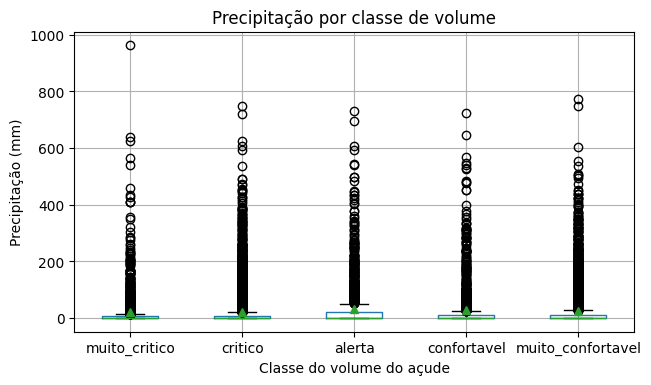

In [21]:
quanti, quali = "precipitação", "classe_volume_acude"
ALPHA = 0.05

ordem = ["muito_critico", "critico", "alerta", "confortavel", "muito_confortavel"]
ordem = [o for o in ordem if o in df_final[quali].dropna().unique()]

dq = df_final[[quanti, quali]].dropna().copy()
dq[quali] = pd.Categorical(dq[quali], categories=ordem, ordered=True)
print("n =", len(dq))

# 1) Descritiva por grupo
print(dq.groupby(quali, observed=True)[quanti].describe().round(2))

ax = dq.boxplot(column=quanti, by=quali, figsize=(7, 4), showmeans=True)
ax.set_ylabel("Precipitação (mm)")
ax.set_xlabel("Classe do volume do açude")
plt.suptitle("")
plt.title("Precipitação por classe de volume")
plt.show()

In [22]:
# 2) ANOVA
d_aov = dq.rename(columns={quanti: "precip", quali: "classe"})
model = ols("precip ~ C(classe)", data=d_aov).fit()
aov_table = sm.stats.anova_lm(model, typ=2)
print(aov_table, "\n")

# 3a) Normalidade dos resíduos (H0: normais)
ks = stats.kstest(model.resid, stats.norm.cdf, args=(model.resid.mean(), model.resid.std()))
print("KS resíduos:", ks)

# 3b) Homogeneidade de variâncias (H0: variâncias iguais)
grupos = [g[quanti].dropna() for _, g in dq.groupby(quali, observed=True)]
lev = stats.levene(*grupos)
print("Levene:", lev)

normal = ks.pvalue >= ALPHA
homogeneo = lev.pvalue >= ALPHA
print("\nNormalidade dos resíduos:", "não rejeitada" if normal else "REJEITADA")
print("Homogeneidade de variâncias:", "não rejeitada" if homogeneo else "REJEITADA")
usar_anova = normal and homogeneo
print("Teste adequado:", "ANOVA" if usar_anova else "Kruskal-Wallis")

                 sum_sq       df         F        PR(>F)
C(classe)  1.484196e+05      4.0  8.552396  6.878519e-07
Residual   5.956813e+07  13730.0       NaN           NaN 

KS resíduos: KstestResult(statistic=np.float64(0.3332545158081953), pvalue=np.float64(0.0), statistic_location=np.float64(-11.0703763657055), statistic_sign=np.int8(1))
Levene: LeveneResult(statistic=np.float64(8.551032917385623), pvalue=np.float64(6.896212765324868e-07))

Normalidade dos resíduos: REJEITADA
Homogeneidade de variâncias: REJEITADA
Teste adequado: Kruskal-Wallis


In [24]:
# 4) Kruskal-Wallis
H, p_kw = stats.kruskal(*grupos)
n = sum(len(g) for g in grupos)
eps2 = H / (n - 1)   # tamanho de efeito: ~0,01 pequeno | ~0,06 médio | ~0,14 grande
print(f"Kruskal-Wallis: H = {H:.2f}, p = {p_kw:.4g}, epsilon² = {eps2:.4f}")
print("Decisão:", "rejeita H0 (há associação)" if p_kw < ALPHA else "não rejeita H0 (sem evidência de associação)")

print()
print(dq.groupby(quali, observed=True)[quanti].agg(["count", "mean", "median"]).round(2))

Kruskal-Wallis: H = 64.25, p = 3.699e-13, epsilon² = 0.0047
Decisão: rejeita H0 (há associação)

                     count   mean  median
classe_volume_acude                      
muito_critico         1541  19.76    0.00
critico               4860  21.92    0.00
alerta                1669  31.30    0.27
confortavel           1428  26.65    0.00
muito_confortavel     4237  24.38    0.00


In [26]:
# Comparações múltiplas (post hoc): Tukey após ANOVA | Dunn após Kruskal-Wallis
if usar_anova:
    comp = mc.MultiComparison(dq[quanti], dq[quali].astype(str))
    print(comp.tukeyhsd().summary())
else:
    try:
        import scikit_posthocs as sp          # pip install scikit-posthocs
        print(sp.posthoc_dunn(dq, val_col=quanti, group_col=quali, p_adjust="bonferroni").round(4))
    except ImportError:
        print("Para o post hoc de Dunn: pip install scikit-posthocs")

                   muito_critico  critico  alerta  confortavel  \
muito_critico             1.0000   0.5713     0.0       1.0000   
critico                   0.5713   1.0000     0.0       1.0000   
alerta                    0.0000   0.0000     1.0       0.0000   
confortavel               1.0000   1.0000     0.0       1.0000   
muito_confortavel         0.0011   0.0478     0.0       0.5723   

                   muito_confortavel  
muito_critico                 0.0011  
critico                       0.0478  
alerta                        0.0000  
confortavel                   0.5723  
muito_confortavel             1.0000  


### Variante: dependente binária (`bin_status_alerta`)

Com dois grupos, o fluxo é o mesmo (o script05 usa `kruskal` com dois grupos); o Mann-Whitney é o equivalente.

In [27]:
d2 = df_final[[quanti, "bin_status_alerta"]].dropna()
g0 = d2.loc[d2["bin_status_alerta"] == 0, quanti]
g1 = d2.loc[d2["bin_status_alerta"] == 1, quanti]
print(f"n (alerta=0): {len(g0)} | n (alerta=1): {len(g1)}")
print(f"Mediana (alerta=0): {g0.median():.2f} | Mediana (alerta=1): {g1.median():.2f}")
print("Levene:", stats.levene(g0, g1))
print("Kruskal-Wallis:", stats.kruskal(g0, g1))
print("Mann-Whitney:", stats.mannwhitneyu(g0, g1))

n (alerta=0): 6401 | n (alerta=1): 7334
Mediana (alerta=0): 0.00 | Mediana (alerta=1): 0.00
Levene: LeveneResult(statistic=np.float64(19.695528111052568), pvalue=np.float64(9.152096473564e-06))
Kruskal-Wallis: KruskalResult(statistic=np.float64(28.752386410544677), pvalue=np.float64(8.224850953770867e-08))
Mann-Whitney: MannwhitneyuResult(statistic=np.float64(22343663.0), pvalue=np.float64(8.22495912956246e-08))


---
## QUESTÃO 3: transformação da quantitativa em qualitativa (intervalos)

Só entram as quantitativas **associadas estatisticamente à dependente** na Questão 2. A precipitação foi significativa, então é discretizada.

**Critérios dos intervalos**
- Cortes por **intensidade de chuva** (contexto meteorológico), em vez de quantis: a maioria dos dias tem 0 mm, e os quantis repetiriam limites.
- **Faixa própria para 0 mm** (dia seco).
- Faixas **mutuamente exclusivas** e que **cobrem todo o domínio** (limites com `>` e `<=`; última faixa aberta, > 50 mm).

**Por que transformar:** facilita a interpretação ("chuva forte" em vez de mm exatos), reduz o peso de valores extremos e permite usar a variável em modelos para dados categóricos (como a rede bayesiana).

In [28]:
p_mm = df_final["precipitação"]

condicoes = [
    (p_mm == 0.0),
    (p_mm > 0.0)  & (p_mm <= 1.0),
    (p_mm > 1.0)  & (p_mm <= 10.0),
    (p_mm > 10.0) & (p_mm <= 20.0),
    (p_mm > 20.0) & (p_mm <= 30.0),
    (p_mm > 30.0) & (p_mm <= 40.0),
    (p_mm > 40.0) & (p_mm <= 50.0),
    (p_mm > 50.0),
]
rotulos = ["Sem_Precipitação", "Chuvisco", "Fraca", "Moderada",
           "Moderada_a_Forte", "Forte", "Muito_Forte", "Violenta"]

classe = np.select(condicoes, rotulos, default="sem_classe")
df_final["classe_precipitacao"] = pd.Categorical(classe, categories=rotulos, ordered=True)
df_final.loc[p_mm.isna(), "classe_precipitacao"] = np.nan

# versão binária: choveu (1) ou não (0)
df_final["bin_choveu"] = (p_mm > 0.0).astype("Int64").where(p_mm.notna())

print("Valores sem classe:", df_final["classe_precipitacao"].isna().sum())
freq = df_final["classe_precipitacao"].value_counts().sort_index()
display(pd.DataFrame({"n": freq, "%": (freq / freq.sum() * 100).round(2)}))

Valores sem classe: 2


C:\Users\Rebeca\AppData\Local\Temp\ipykernel_14964\1629862890.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  df_final["classe_precipitacao"] = pd.Categorical(classe, categories=rotulos, ordered=True)


,n,%
classe_precipitacao,,
Sem_Precipitação,8440,55.70
Chuvisco,969,6.40
Fraca,1881,12.41
Moderada,762,5.03
Moderada_a_Forte,459,3.03
Forte,357,2.36
Muito_Forte,282,1.86
Violenta,2002,13.21


In [29]:
tab = pd.crosstab(df_final["classe_precipitacao"], df_final["classe_volume_acude"])
tab = tab.reindex(columns=[o for o in ordem if o in tab.columns])
display(tab)

chi2, p_chi, gl, esp = stats.chi2_contingency(tab)
n = tab.values.sum()
v = (chi2 / (n * (min(tab.shape) - 1))) ** 0.5

print(f"chi2 = {chi2:.2f}, gl = {gl}, p = {p_chi:.4g}, V de Cramér = {v:.3f}")
print(f"Células com frequência esperada <= 5: {(esp <= 5).sum()} de {esp.size}")
print("Decisão:", "rejeita H0 (há associação)" if p_chi < ALPHA else "não rejeita H0")

classe_volume_acude,muito_critico,critico,alerta,confortavel,muito_confortavel
classe_precipitacao,,,,,
Sem_Precipitação,925,2797,821,835,2309
Chuvisco,106,310,96,79,283
Fraca,167,582,224,158,566
Moderada,68,234,106,63,212
Moderada_a_Forte,51,147,47,41,128
Forte,30,101,53,39,99
Muito_Forte,26,82,32,25,83
Violenta,168,607,290,188,557


chi2 = 86.76, gl = 28, p = 6.307e-08, V de Cramér = 0.040
Células com frequência esperada <= 5: 0 de 40
Decisão: rejeita H0 (há associação)


In [30]:
# Caso 2x2: bin_choveu x bin_status_alerta (Fisher se houver frequência esperada baixa)
tab2 = pd.crosstab(df_final["bin_choveu"], df_final["bin_status_alerta"])
display(tab2)
chi2b, pb, glb, espb = stats.chi2_contingency(tab2)
print(f"Qui-quadrado: chi2 = {chi2b:.2f}, p = {pb:.4g}")
if (espb <= 5).any():
    print("Fisher exato:", stats.fisher_exact(tab2))

bin_status_alerta,0,1
bin_choveu,,
0,3722,3965
1,2679,3369


Qui-quadrado: chi2 = 22.97, p = 1.649e-06


---
## QUESTÃO 4: Esboçando o grafo da Rede Bayesiana do seu problema.


A rede tem cinco variáveis, todas discretizadas em classes: Mês, Açude, Precipitação,
Volume Anterior e Volume Atual (variável dependente). Mês, Açude e Volume Anterior são
nós raiz; Precipitação depende apenas do Mês; Volume Atual é o nó final, com três pais.

**Relações (arestas)**

- **Precipitação → Volume Atual:** o teste qui-quadrado da Questão 3 indicou associação
  estatisticamente significativa entre a classe de precipitação e a classe de volume do
  açude (χ² = 86,76; gl = 28; p = 6,3×10⁻⁸). O V de Cramér (0,040) mostra que a
  associação é de pequena magnitude, o que é esperado: o volume de hoje depende
  sobretudo do volume anterior, e a chuva atua como um fator adicional de recarga.
  Mantém-se a aresta pela significância do teste e pelo sentido físico (a chuva
  recarrega o reservatório).

- **Volume Anterior → Volume Atual:** o reservatório tem "memória". O nível de hoje parte
  do nível do registro anterior e só muda gradualmente com entradas (chuva) e saídas
  (evaporação, consumo).
- **Açude → Volume Atual:** os quatro açudes têm capacidades muito diferentes
  (de 19,2 a 72,6 hm³) e bacias distintas, então a mesma chuva produz respostas
  diferentes em cada um.
- **Mês → Precipitação:** a chuva no Nordeste é fortemente sazonal, com estação chuvosa
  e estação seca bem definidas.
- **Mês → Volume Atual** *(inclua apenas se mantiver essa aresta)*: além do efeito via
  chuva, o mês influencia diretamente o volume por evaporação e consumo sazonais.

In [40]:
"""
Como não temos no df_final a uma variável para o Volume anterior por açude, vamos criá-la

no sort_values agrupamos as linhas por açude e, dentro de cada açude, coloca em ordem de data.
Sem isso o shift pegaria uma linha qualquer, e não a anterior no tempo.

groupby("acude") faz a operação separadamente para cada açude. Assim a primeira linha de um
açude não herda o valor do último de outro.

["classe_volume_acude"].shift(1) desce a coluna uma posição. Cada linha passa a ter o valor da linha de cima.

Por fim extraimos o número do mês (1 a 12) da data. É o nó mes do grafo, que captura a sazonalidade da chuva.
"""
df_final = df_final.sort_values(["acude", "Data"]).reset_index(drop=True)

df_final["classe_volume_anterior"] = (df_final.groupby("acude")["classe_volume_acude"].shift(1))

df_final["mes"] = pd.to_datetime(df_final["Data"]).dt.month

nós: ['Mês', 'Precipitação', 'Volume_Atual', 'Volume_Anterior', 'Açude']
arestas: [('Mês', 'Precipitação'), ('Precipitação', 'Volume_Atual'), ('Volume_Anterior', 'Volume_Atual'), ('Açude', 'Volume_Atual')]


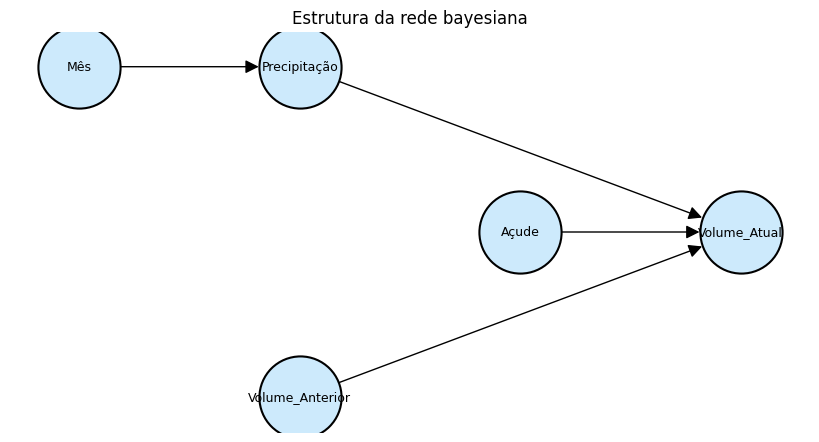

In [44]:
Gnew = nx.DiGraph() #Novo grafo direcionado (DAG) 
 
Gnew.add_edges_from([ # adicionando as arestas (relacionamentos) entre as variáveis
    ("Mês",             "Precipitação"),
    ("Precipitação",    "Volume_Atual"),
    ("Volume_Anterior", "Volume_Atual"),
    ("Açude",           "Volume_Atual"),
])

assert nx.is_directed_acyclic_graph(Gnew), "A rede bayesiana não pode ter ciclos" # verifica se o grafo é acíclico (DAG)

pos = { # posições dos nós no grafo
    "Mês":             (0, 1),
    "Precipitação":    (1, 1),
    "Volume_Anterior": (1, -1),
    "Açude":           (2, 0),
    "Volume_Atual":    (3, 0),
}

plt.figure(figsize=(8, 4))

nx.draw(
    Gnew,
    pos,
    with_labels=True,
    node_size=3500,
    node_color='#cdeafc',
    edgecolors='black',
    linewidths=1.5,
    font_size=9,
    arrowsize=20,

    arrows=True
)

print("nós:", Gnew.nodes()) #mostra os nós
print("arestas:", Gnew.edges()) #mostra as arestas

plt.title("Estrutura da rede bayesiana")
plt.axis('off')

plt.show()


## Houve mudança na estrutura da rede em relação ao Teste 04?

Sim. Foi incluído o nó **Açude (A)** e a aresta **Açude → Volume Atual (Vₜ)**. No Teste 04
a rede tratava o reservatório de forma única, já agora os dados reúnem quatro açudes (Atalho,
Rosário, Olho d'Água e Quixabinha), com capacidades de 19,2 a 72,6 hm³. Por isso, a mesma
chuva ou o mesmo volume anterior pode resultar em classes de volume diferentes conforme o
açude.

Também mudou a discretização das variáveis: o volume passou de 3 para 5 classes, definidas
pelo percentual da capacidade máxima de cada açude, e a precipitação passou a ser a classe
diária (8 faixas), em vez da acumulada recente. A memória hidrológica ficou limitada ao
volume do registro anterior (Vₜ₋₁).

Portanto, concluimos que a rede resultante é acíclica e tem o volume atual como nó final. Seus pais (mês,
precipitação, volume anterior e açude) reúnem os fatores climáticos, a memória do
reservatório e as características de cada açude.